# WCU readout playground (LM / N)

Set the filter, masks and integration below, then run the cells to get a ScopeSim readout of the
WCU and display it. Uses the same set-up as the SIM scripts (`modules.sim_common`).

In [40]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from astropy import units as u

# put main_scripts/ (for `modules`) on the path
ROOT = Path.cwd().resolve()
while not (ROOT / "main_scripts").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "main_scripts"))

from modules import sim_common
from modules.config_common import load_observing_config
from modules.paths import project_root

sim_common.setup_scopesim()
observing = load_observing_config(project_root())

root - IRDB directory: /home/eckhart/Documents/git.repos/metis_work/METIS_MAIT_code_eckhart/irdb/
root - --------------------------------
root - ScopeSim bug report
root - Python:
root - 3.12.16 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 20:21:38) [GCC 14.3.0]
root - 
root - Installed Python packages:
root -            anisocado: 0.6.0
root -          astar-utils: 0.7.0
root -              astropy: 8.0.2
root -       beautifulsoup4: 4.15.0
root -             docutils: 0.23
root -              httpxyz: 0.42.1
root -                 lxml: 6.1.3
root -           matplotlib: 3.11.2
root -       more-itertools: 10.8.0
root -                numpy: 2.5.4
root -            packaging: 26.3
root -                pooch: 1.9.0
root -               pyyaml: 6.0.3
root -                scipy: 1.17.1
root -             scopesim: 0.12.0
root -        scopesim_data: could not be loaded.
root -   scopesim_templates: could not be loaded.
root -          skycalc-ipy: 0.8.0
root -              synph

## Settings

- `obs_mode`: `wcu_img_lm` or `wcu_img_n`
- `fp_mask`: `open` (flat), `pinhole_lm`, `pinhole_n`, `grid_lm`
- `pp_mask`: e.g. `PPS-CFO2`, `SPM-LM`, `CLS-LM`, `SPM-N`, `CLS-N`; `psf_kernel`: `None` = `<pp_mask>_WCU`
- `nd_filter`: `None`, `ND_OD1` ... `ND_OD4`
- `dit` (s), `ndit`; `bb_aperture` (0 = closed, 1 = open); `bb_temp_k`

In [41]:
instrument = {
    "obs_mode": "wcu_lss_l",
    "obs_filter": "L_spec",
    "fp_mask": "pinhole_lm",
    "pp_mask": "PPS-CFO2",
    "psf_kernel": None,
    "nd_filter": None,
    "dit": 0.04,
    "ndit": 1,
    "intrapixel_capacitance": True,
}
bb_aperture = 1.0
bb_temp_k = 1000
subtract_dark = True  # also read out a dark (BB aperture closed) and subtract it

In [42]:
metis = sim_common.build_optical_train(instrument)
metis["wcu_source"].set_temperature(bb_temp=bb_temp_k * u.K)

frame, header = sim_common.readout_frame(metis, bb_aperture, instrument)
dark = sim_common.readout_frame(metis, 0.0, instrument)[0] if subtract_dark else None

saturation = sim_common.saturation_of(observing, sim_common.detector_key(instrument["obs_mode"]))
print(f"raw: median {np.median(frame):.4g}, max {np.max(frame):.4g} ADU "
      f"= {np.max(frame) / saturation:.3f} of saturation ({saturation:.0f} ADU)")

root - Using default inter-pixel capacitance
astar.scopesim.effects.ter_curves - WARNING: 
Pupil mask has been changed; don't forget to update the PSF:
	 metis['psf'].update(pupil_mask="PPS-CFO2")
root - WCU PP mask: PPS-CFO2; PSF kernel: PPS-CFO2_WCU
root - --------------------------------
root - Optical train effects (initial)
root -     element                  name                       class             included
root - ---------------- --------------------------- ---------------------------- --------
root -        METIS_WCU                  wcu_source                    WCUSource     True
root -        METIS_WCU            wcu_relay_optics                  SurfaceList     True
root -        METIS_WCU    pupil_masks : [PPS-CFO2]               PupilMaskWheel PPS-CFO2
root -        METIS_WCU           wcu_fits_keywords            ExtraFitsKeywords     True
root -            METIS          common_fore_optics                  SurfaceList     True
root -            METIS      adc_wheel 

 FOVs:   0%|          | 0/18 [00:00<?, ?it/s]

astar.scopesim.effects.psfs - Interpolating PSF onto (178, 15, 256) cube
astar.scopesim.effects.psfs - Interpolation order 1



 FOV effects: 100%|██████████| 2/2 [00:00<00:00,  4.23it/s]

astar.scopesim.optics.image_plane - No BUNIT found in added HDU.



 FOVs:   6%|▌         | 1/18 [00:00<00:10,  1.57it/s]

... (141 outputs left out)

astar.scopesim.optics.image_plane - No BUNIT found in added HDU.



 FOVs: 100%|██████████| 18/18 [00:10<00:00,  1.67it/s]

astar.scopesim.effects.electronic - WARNING: DIT = 0.040 s < MINDIT = 1.300 s
astar.scopesim.effects.electronic - Exposure parameters: DIT = 0.040 s, NDIT = 1
astar.scopesim.effects.electronic - Total exposure time: 0.040 s
astar.scopesim.detector.detector_manager - Extracting from 1 detectors...
astar.scopesim.effects.electronic - Applying border [64, 64, 64, 64]


astar.scopesim.effects.electronic - Applying gain 2.5
astar.scopesim.effects.electronic - WARNING: DIT = 0.040 s < MINDIT = 1.300 s
astar.scopesim.effects.electronic - Exposure parameters: DIT = 0.040 s, NDIT = 1
astar.scopesim.effects.electronic - Total exposure time: 0.040 s
root - Read out frame: BB aperture 0.0000, DIT 0.04 s, NDIT 1, median 31.8, max 503 counts
raw: median 32.2, max 2126 ADU = 0.085 of saturation (25000 ADU)


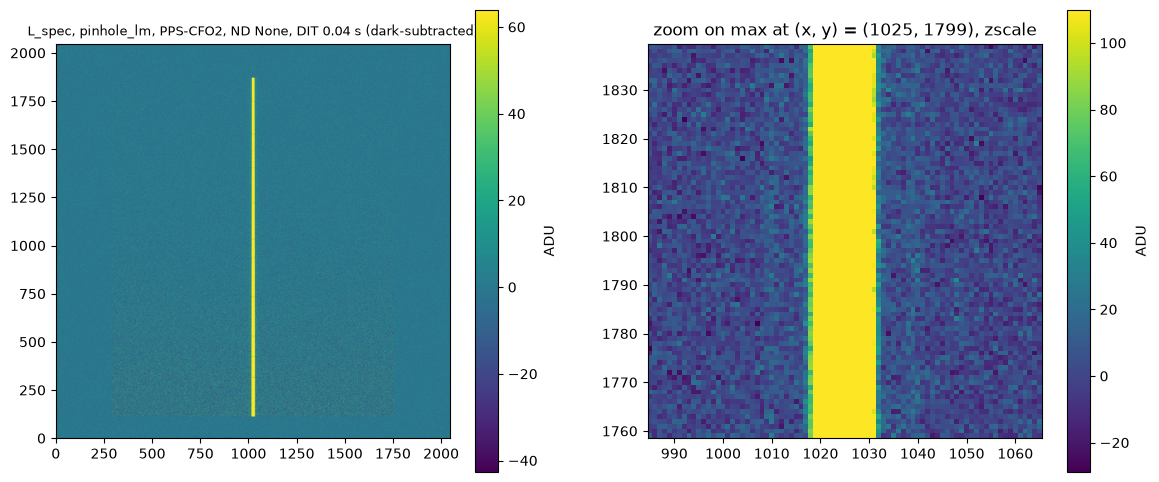

In [43]:
from astropy.visualization import ZScaleInterval

image = frame - dark if subtract_dark else frame
title = (f"{instrument['obs_filter']}, {instrument['fp_mask']}, {instrument['pp_mask']}, "
         f"ND {instrument['nd_filter']}, DIT {instrument['dit']} s"
         + (" (dark-subtracted)" if subtract_dark else ""))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
zscale = ZScaleInterval()
lo, hi = zscale.get_limits(image)
im = axes[0].imshow(image, origin="lower", vmin=lo, vmax=hi)
axes[0].set_title(title, fontsize=9)
fig.colorbar(im, ax=axes[0], label="ADU")
# zoom around the brightest pixel, e.g. a pinhole PSF (zscale of the cutout)
half = 40  # half-width of the zoom (pixels)
y0, x0 = np.unravel_index(np.argmax(image), image.shape)
ys, xs = slice(max(y0 - half, 0), y0 + half + 1), slice(max(x0 - half, 0), x0 + half + 1)
cut = image[ys, xs]
lo, hi = zscale.get_limits(cut)
im = axes[1].imshow(cut, origin="lower", vmin=lo, vmax=hi,
                    extent=(xs.start - 0.5, xs.stop - 0.5, ys.start - 0.5, ys.stop - 0.5))
axes[1].set_title(f"zoom on max at (x, y) = ({x0}, {y0}), zscale")
fig.colorbar(im, ax=axes[1], label="ADU")
plt.show()

In [44]:
# save a FITS file like the SIM scripts: header-only primary, then
# BCKGD_SUBTED (raw - background), RAW_READOUT and BACKGROUND (the dark)
from astropy.io import fits

out_file = ROOT / "data" / "frame.fits"
out_file.parent.mkdir(parents=True, exist_ok=True)

fits.HDUList([
    fits.PrimaryHDU(header=header),
    fits.ImageHDU(data=(frame - dark).astype(np.float32), name="BCKGD_SUBTED"),
    fits.ImageHDU(data=frame.astype(np.float32), name="RAW_READOUT"),
    fits.ImageHDU(data=dark.astype(np.float32), name="BACKGROUND"),
]).writeto(out_file, overwrite=True)
print(out_file)

/home/eckhart/Documents/git.repos/metis_work/METIS_MAIT_code_eckhart/data/frame.fits


## Wavelength solution (LSS modes only)

ScopeSim's `spectral_traces` effect maps focal-plane (x, y) [mm] to wavelength [um]
(`trace.xy2lam`) and slit position xi [arcsec] (`trace.xy2xi`); detector pixels are
converted to mm with the IRDB detector layout file. Dispersion is along the rows.
The spectrum is summed over the illuminated slit columns, and only rows inside the
trace table's wavelength range are kept.

trace METIS LSS L: 2.900-4.200 um; 4 slit columns; dispersion -0.740 nm/pix


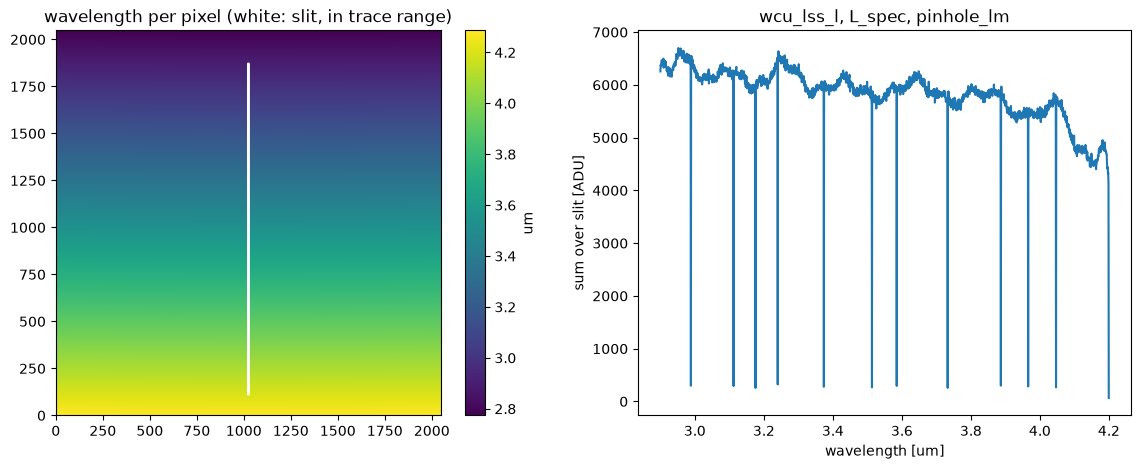

In [45]:
# Wavelength solution (LSS modes) and the slit-collapsed spectrum vs. wavelength
from astropy.io import ascii

# pixel -> focal-plane mm, from the detector layout file in the IRDB
layout_file = {
    "img_lm": "FPA_metis_img_lm_layout.dat",
    "img_n": "FPA_metis_img_n_geosnap_layout.dat",
}[sim_common.detector_key(instrument["obs_mode"])]
layout = ascii.read(Path(sim_common.IRDB_DIR) / "METIS" / layout_file)
pix_mm = float(layout["pixel_size" if "pixel_size" in layout.colnames else "pixsize"][0])

# ScopeSim's fitted trace transforms: (x, y) [mm] -> wavelength [um] and slit position [arcsec]
trace = next(iter(metis["spectral_traces"].spectral_traces.values()))
ny, nx = frame.shape
cols, rows = np.meshgrid(np.arange(nx), np.arange(ny))
x_mm = (cols - (nx - 1) / 2) * pix_mm + float(layout["x_cen"][0])
y_mm = (rows - (ny - 1) / 2) * pix_mm + float(layout["y_cen"][0])
lam_map = trace.xy2lam(x_mm, y_mm, grid=False)  # um, per pixel
xi_map = trace.xy2xi(x_mm, y_mm, grid=False)    # arcsec along the slit, per pixel

# slit-collapsed spectrum: sum over the illuminated columns (dispersion is along the
# rows), keeping only rows inside the trace table's wavelength range (no extrapolation)
image = frame - dark if subtract_dark else frame
profile = np.median(image, axis=0)
slit_cols = profile > 0.5 * np.max(profile)
spectrum = image[:, slit_cols].sum(axis=1)
lam_rows = np.median(lam_map[:, slit_cols], axis=1)
in_range = (lam_rows >= trace.wave_min) & (lam_rows <= trace.wave_max)
print(f"trace {trace.trace_id}: {trace.wave_min:.3f}-{trace.wave_max:.3f} um; "
      f"{slit_cols.sum()} slit columns; "
      f"dispersion {np.median(np.diff(lam_rows[in_range])) * 1e3:.3f} nm/pix")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
im = axes[0].imshow(lam_map, origin="lower")
axes[0].contour(slit_cols[None, :] & in_range[:, None], levels=[0.5], colors="w")
axes[0].set_title("wavelength per pixel (white: slit, in trace range)")
fig.colorbar(im, ax=axes[0], label="um")
axes[1].plot(lam_rows[in_range], spectrum[in_range])
axes[1].set_xlabel("wavelength [um]")
axes[1].set_ylabel("sum over slit [ADU]")
axes[1].set_title(f"{instrument['obs_mode']}, {instrument['obs_filter']}, {instrument['fp_mask']}")
plt.show()

In [46]:
type(frame)

numpy.ndarray